In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/isp_bersih_berlabel.csv")
urut = ["Baik", "Sedang", "Buruk"]
warna = {"Baik": "#2e7d32", "Sedang": "#f9a825", "Buruk": "#c62828"}

fitur = ["sample_count",
         "download_average", "download_p25", "download_p75",
         "upload_average",   "upload_p25",   "upload_p75",
         "ping_average",     "ping_p25",     "ping_p75"]

print(df.shape)
df.head()

(98, 18)


,bulan,name,country,sample_count,download_median,upload_median,ping_median,download_average,download_p25,download_p75,upload_average,upload_p25,upload_p75,ping_average,ping_p25,ping_p75,skor,kualitas
0,2026-01,Spectrum (Charter),US,155,369.36,29.99,32.0,412.79,151.76,603.75,42.37,12.25,39.90,33.95,26.00,39.50,6,Baik
1,2026-01,AT&T,US,54,258.63,151.68,25.5,341.35,129.94,510.02,218.13,29.14,357.18,35.52,19.25,33.75,6,Baik
2,2026-01,Xfinity (Comcast),US,123,192.30,42.50,30.0,314.14,87.93,483.99,87.51,28.53,95.40,32.25,20.00,36.50,6,Baik
3,2026-01,Cox,US,25,270.12,33.45,28.0,273.01,170.88,376.81,55.87,11.27,53.01,29.52,19.00,41.00,6,Baik
4,2026-01,Verizon,US,43,211.26,67.07,28.0,236.59,59.43,331.32,119.83,11.40,138.80,35.60,13.00,55.00,6,Baik


In [2]:
df.info()
print()
print("Missing:", df.isna().sum().sum())
print("Jumlah ISP unik:", df["name"].nunique())
print("Jumlah negara:", df["country"].nunique())
print("Periode:", df["bulan"].min(), "sampai", df["bulan"].max())


<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   bulan             98 non-null     str    
 1   name              98 non-null     str    
 2   country           98 non-null     str    
 3   sample_count      98 non-null     int64  
 4   download_median   98 non-null     float64
 5   upload_median     98 non-null     float64
 6   ping_median       98 non-null     float64
 7   download_average  98 non-null     float64
 8   download_p25      98 non-null     float64
 9   download_p75      98 non-null     float64
 10  upload_average    98 non-null     float64
 11  upload_p25        98 non-null     float64
 12  upload_p75        98 non-null     float64
 13  ping_average      98 non-null     float64
 14  ping_p25          98 non-null     float64
 15  ping_p75          98 non-null     float64
 16  skor              98 non-null     int64  
 17  kualitas  

In [3]:
df[["download_median", "upload_median", "ping_median"]].describe().round(2)

,download_median,upload_median,ping_median
count,98.00,98.00,98.00
mean,183.19,47.85,57.94
std,149.06,43.22,52.36
min,18.77,4.20,7.00
25%,63.64,16.76,30.00
50%,143.68,34.94,41.50
75%,269.94,66.72,60.75
max,843.01,204.99,254.50


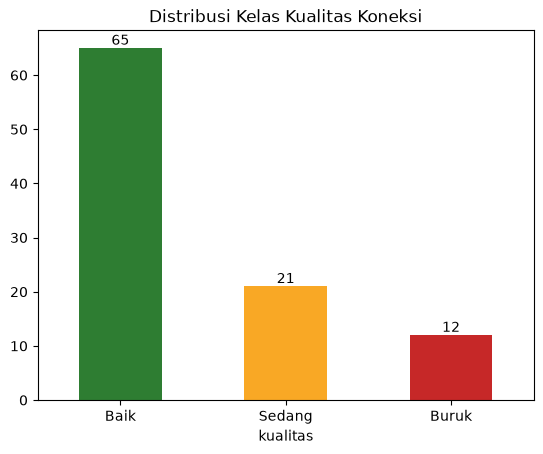

kualitas
Baik      66.3
Sedang    21.4
Buruk     12.2
Name: proportion, dtype: float64


In [4]:
ax = df["kualitas"].value_counts().reindex(urut).plot(
    kind="bar", color=[warna[k] for k in urut])
ax.bar_label(ax.containers[0])
plt.title("Distribusi Kelas Kualitas Koneksi")
plt.xticks(rotation=0)
plt.savefig("data/processed/eda_1_distribusi_kelas.png", dpi=200, bbox_inches="tight")
plt.show()

print((df["kualitas"].value_counts(normalize=True) * 100).round(1))

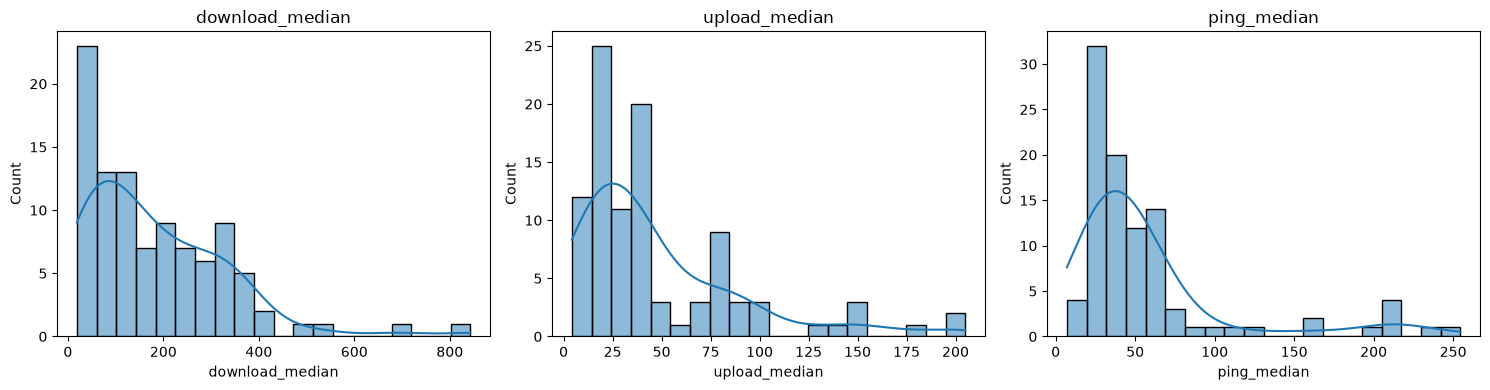

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["download_median", "upload_median", "ping_median"]):
    sns.histplot(df[m], bins=20, kde=True, ax=a)
    a.set_title(m)
plt.tight_layout()
plt.savefig("data/processed/eda_2_histogram_metrik.png", dpi=200, bbox_inches="tight")
plt.show()

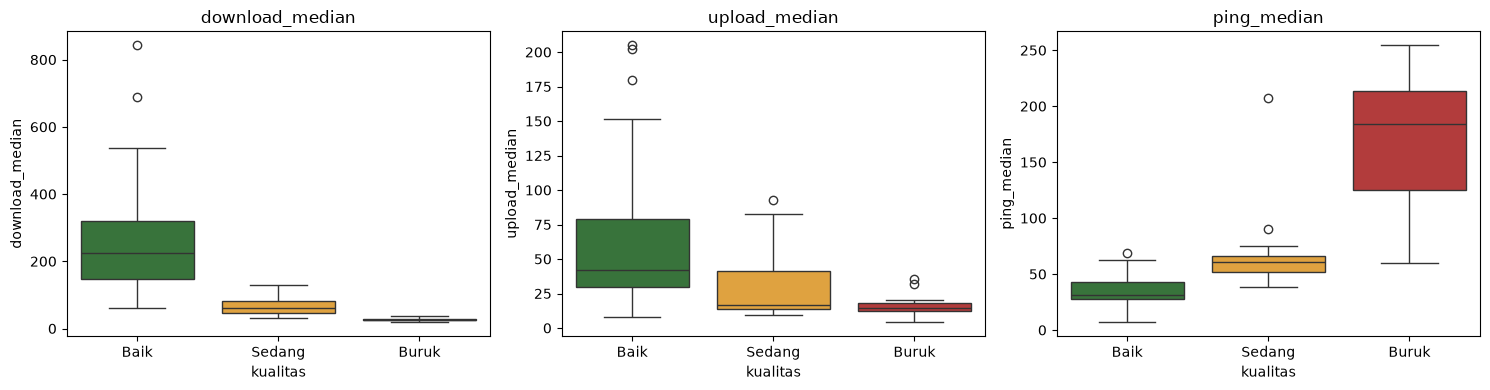

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["download_median", "upload_median", "ping_median"]):
    sns.boxplot(data=df, x="kualitas", y=m, order=urut,
                hue="kualitas", palette=warna, legend=False, ax=a)
    a.set_title(m)
plt.tight_layout()
plt.savefig("data/processed/eda_3_metrik_per_kelas.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
tabel = df.groupby("kualitas")[["download_median", "upload_median", "ping_median"]] \
          .agg(["mean", "median", "min", "max"]).round(1).loc[urut]
tabel

download_median                     upload_median                     \
                    mean median   min    max          mean median  min    max   
kualitas                                                                        
Baik               250.1  225.3  59.8  843.0          59.1   41.9  7.6  205.0   
Sedang              65.4   62.1  29.8  130.5          30.7   16.4  9.1   92.5   
Buruk               26.8   26.4  18.8   37.9          16.7   14.8  4.2   35.3   

         ping_median                      
                mean median   min    max  
kualitas                                  
Baik            34.4   31.0   7.0   69.0  
Sedang          65.9   61.0  38.5  207.0  
Buruk          171.2  184.5  60.0  254.5

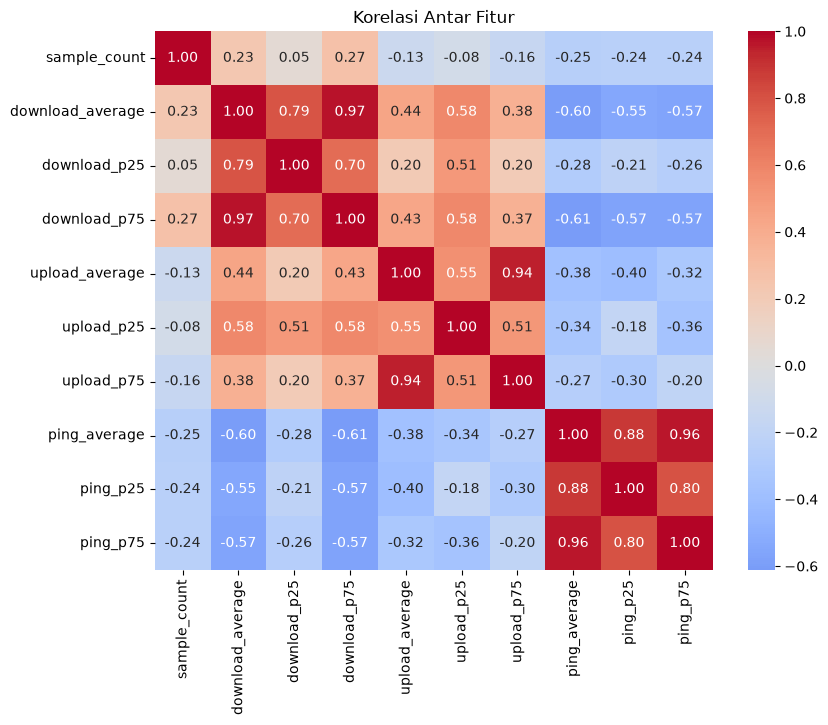

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[fitur].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Antar Fitur")
plt.savefig("data/processed/eda_4_korelasi.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
pd.crosstab(df["country"], df["kualitas"])[urut]

kualitas,Baik,Sedang,Buruk
country,,,
AU,0,0,1
BD,0,0,1
CA,3,1,1
ES,5,0,0
GB,0,1,0
ID,0,1,8
IN,0,0,1
MX,3,5,0
PH,0,1,0


In [10]:
pd.crosstab(df["bulan"], df["kualitas"])[urut]

kualitas,Baik,Sedang,Buruk
bulan,,,
2026-01,8,2,4
2026-02,9,2,4
2026-03,9,3,1
2026-04,6,4,1
2026-05,4,1,0
2026-06,6,1,0
2026-07,7,3,0
2026-08,9,2,1
2026-09,7,3,1


In [11]:
df[df["country"] == "ID"][["bulan", "name", "sample_count",
                           "download_median", "upload_median", "ping_median", "kualitas"]]

,bulan,name,sample_count,download_median,upload_median,ping_median,kualitas
11,2026-01,Telkom Indonesia,118,32.00,15.12,213.5,Buruk
12,2026-01,Indosat,41,18.77,15.09,95.0,Buruk
13,2026-01,Telkomsel,57,29.51,8.64,213.0,Buruk
26,2026-02,Indosat,20,26.58,19.96,166.5,Buruk
27,2026-02,Telkom Indonesia,57,24.46,14.34,111.0,Buruk
28,2026-02,Telkomsel,38,24.84,14.61,202.5,Buruk
40,2026-03,Telkom Indonesia,31,49.24,21.14,207.0,Sedang
41,2026-03,Telkomsel,21,26.12,11.37,235.0,Buruk
52,2026-04,Telkom Indonesia,30,29.17,12.24,213.0,Buruk


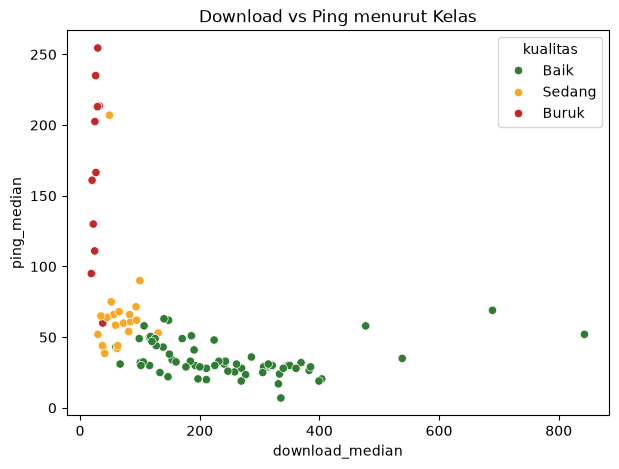

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="download_median", y="ping_median",
                hue="kualitas", hue_order=urut, palette=warna)
plt.title("Download vs Ping menurut Kelas")
plt.savefig("data/processed/eda_5_download_vs_ping.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
import os
print([f for f in os.listdir("data/processed") if f.startswith("eda_")])

['eda_1_distribusi_kelas.png', 'eda_2_histogram_metrik.png', 'eda_3_metrik_per_kelas.png', 'eda_4_korelasi.png', 'eda_5_download_vs_ping.png']


## Temuan EDA

1. Data berjumlah 98 baris (ISP per bulan) dari 26 ISP dan 11 negara, periode 2026-01 sampai 2026-09, tanpa missing value.
2. Kelas tidak seimbang: Baik 65 (66,3%), Sedang 21 (21,4%), Buruk 12 (12,2%). Evaluasi karena itu memakai F1-macro dan cross-validation berstrata, bukan akurasi saja.
3. Sebaran download, upload, dan ping miring ke kanan, dengan ekor panjang pada ping (hingga sekitar 254 ms).
4. Download paling jelas memisahkan kelas Baik dari Sedang dan Buruk, sedangkan ping paling jelas mencirikan kelas Buruk (median sekitar 185 ms). Pemisahan ini sebagian merupakan konsekuensi dari pembuatan label berbasis median.
5. Fitur sejenis berkorelasi sangat tinggi (download average-p75 0,97; upload average-p75 0,94; ping average-p75 0,96), sehingga Decision Tree cenderung memilih satu fitur wakil. Download dan ping berkorelasi negatif sedang (sekitar -0,6). sample_count hampir tidak berkorelasi dengan fitur lain.
6. Data tidak seimbang secara geografis: AS menyumbang 66 baris, dengan 53 di antaranya kelas Baik (sekitar 82% dari seluruh kelas Baik). Indonesia hanya 9 baris, 8 di antaranya Buruk (sekitar 67% dari seluruh kelas Buruk), dengan ping 95 sampai 235 ms dan download di bawah sekitar 50 Mbps.
7. ISP Indonesia hanya muncul pada Januari sampai April. Kelas Buruk karena itu terkonsentrasi pada Januari dan Februari (8 dari 12 baris) dan hampir tidak ada pada bulan lain. Pola ini mencerminkan komposisi data, bukan tren kualitas internet dari waktu ke waktu.
8. Satu baris Sedang memiliki ping sekitar 207 ms karena skor upload menutupi skor ping, menunjukkan aturan skor bersifat kompensatoris.
